## Analyzing Employer Activity + Zero-Application Job Examples
This notebook covers an analysis on Employer Activity and investigates jobs with zero application in BU CCD Handshake employer engagement data (Spring 2020–Summer 2025).

Contributors: Tessa Thomas

Last Updated: Sunday, March 1, 2026

Documentation link https://docs.google.com/document/d/1Bb41HlLYCEw7ClFDz93oFS0ctIXD8MMtMaOlmVGC6xk/edit?usp=sharing

In [100]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

# ---- File locations ----
# Update DATA_DIR to wherever your CSVs live.
DATA_DIR = "."

#Load in cleaned csv
ep_joined = pd.read_csv(os.path.join(DATA_DIR, "ep_joined.csv"))

# Preview the data
ep_joined.head(5)

C:\Users\tessa\AppData\Local\Temp\ipykernel_19032\116383894.py:13: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  ep_joined = pd.read_csv(os.path.join(DATA_DIR, "ep_joined.csv"))


,name,employer_id,employer_type,employer_creation_date,email,website,employer_size_min,employer_size_max,events_name,event_date,...,employers_name,event_medium,student_attendees_count,employer_name,min_salary,max_salary,job_creation_date,jobs_title,jobs_id,applications_count
0,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",20.0,23.0,2025-02-06,environmental technician,9660425.0,0.0
1,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",0.0,0.0,2024-01-04,entry-level ecologist,8546132.0,0.0
2,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",16.0,16.0,2024-05-08,cultural resource intern,8959118.0,1.0
3,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",0.0,0.0,2023-11-02,environmental technician,8397637.0,0.0
4,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",45000.0,50000.0,2023-10-30,architectural historian,8387960.0,0.0


## Finding Zero-Application Job Examples
This analysis includes August 2025 data

In [101]:
# Make sure job_creation_date is datetime
ep_joined['job_creation_date'] = pd.to_datetime(ep_joined['job_creation_date'], errors='coerce')

# Filter zero-application jobs from large employers in Aug 2025
zero_app_2025 = ep_joined[
    (ep_joined['applications_count'] == 0) &
    ((ep_joined['employer_size_min'] >= 250) | (ep_joined['employer_size_min'].isna())) &
    (ep_joined['job_creation_date'].dt.year == 2025) &
    (ep_joined['job_creation_date'].dt.month == 8) &
    (ep_joined['events_name'].isna())
].drop_duplicates(subset='jobs_id')

# Take a small sample and display key columns
sample_jobs_2025 = zero_app_2025[['jobs_id','jobs_title','employer_name','applications_count','job_creation_date']].head(15)
sample_jobs_2025

,jobs_id,jobs_title,employer_name,applications_count,job_creation_date
26,10110420.0,"assurance intern (las vegas, nv)",eide bailly llp,0.0,2025-08-04
30,10110612.0,"assurance intern (reno, ut)",eide bailly llp,0.0,2025-08-04
32,10110461.0,"entry level tax associate (las vegas, nv)",eide bailly llp,0.0,2025-08-04
51,10110703.0,tax intern (utah),eide bailly llp,0.0,2025-08-04
53,10159741.0,entry level associate (assurance or tax),eide bailly llp,0.0,2025-08-18
54,10159737.0,accounting intern (assurance or tax),eide bailly llp,0.0,2025-08-18
56,10184381.0,tax controversy and procedure intern (fall 2025),eide bailly llp,0.0,2025-08-21
66,10159729.0,accounting intern (assurance or tax),eide bailly llp,0.0,2025-08-18
85,10110382.0,"tax intern (billings, mt)",eide bailly llp,0.0,2025-08-04
86,10113561.0,tax controversy and procedure intern (fall 2025),eide bailly llp,0.0,2025-08-05


In [102]:
#Generates csv file of the sample set and full set
sample_jobs_2025.to_csv(
    "gen_csv/zero_application_examples_2025_top15.csv",
    index=False
)
zero_app_2025.to_csv(
    "gen_csv/zero_applications_2025_full.csv",
    index=False
)

## Analyzing employer activity on Handshake, including job postings and event participation 


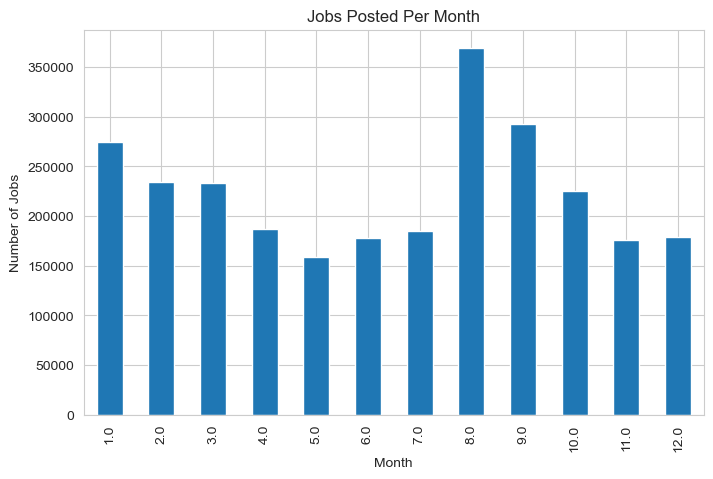

In [103]:
# Extract month
ep_joined['job_month'] = ep_joined['job_creation_date'].dt.month

# Count jobs per month, ignoring missing months
jobs_per_month = ep_joined[ep_joined['job_month'].notna()].groupby('job_month')['jobs_id'].count()

# Plot
plt.figure(figsize=(8,5))
jobs_per_month.plot(kind='bar')
plt.xlabel("Month")
plt.ylabel("Number of Jobs")
plt.title("Jobs Posted Per Month")
plt.show()

## Calculating Job Application Yield 

In [104]:
# Aggregate jobs and applications by employer
employer_jobs = ep_joined.groupby('employer_id')['jobs_id'].nunique()
employer_apps = ep_joined.groupby('employer_id')['applications_count'].sum()

# Combine into df
employer_inf = pd.DataFrame({
    'total_jobs': employer_jobs,
    'total_applications': employer_apps
})

# Calculate JAY
employer_inf['JAY'] = employer_inf['total_applications'] / employer_inf['total_jobs']

# Add employer names
employer_inf['employer_name'] = ep_joined.groupby('employer_id')['employer_name'].first()

**Note:** Job Application Yield (JAY): How frequently/effectively posted jobs attract student applications. 

JAY = Applications Count / Jobs Posted  

In [105]:
# Display top 10 by JAY
top_jay = employer_inf.sort_values('JAY', ascending=False)
top_jay[['employer_name', 'total_jobs', 'total_applications', 'JAY']].head(10)

,employer_name,total_jobs,total_applications,JAY
employer_id,,,,
14072,goldman sachs,164,892551.0,5442.384146
13523,capital one,27,135054.0,5002.000000
8530,kpmg llp,140,683508.0,4882.200000
14620,mckinsey & company,178,692670.0,3891.404494
9226,ey,383,855022.0,2232.433420
13661,morgan stanley,450,989010.0,2197.800000
39013,pwc,221,452395.0,2047.036199
11227,"google, inc.",93,181056.0,1946.838710
12397,fidelity investments,165,197877.0,1199.254545


In [106]:
# Display bottom 10 by JAY
least_jay = employer_inf.sort_values('JAY', ascending=True)
least_jay[['employer_name', 'total_jobs', 'total_applications', 'JAY']].head(10)

,employer_name,total_jobs,total_applications,JAY
employer_id,,,,
1059899,beach tree capital,2,0.0,0.0
1059524,macroreal commercial inc,1,0.0,0.0
1059488,programs for infants and children,1,0.0,0.0
1059433,reroute power pac,1,0.0,0.0
1059391,dovera designs,1,0.0,0.0
1059338,minds matter philadelphia,1,0.0,0.0
1059299,stealth,2,0.0,0.0
1059282,correlate ai,1,0.0,0.0
1059249,gladstone physicians,1,0.0,0.0


In [107]:
#Summary Stats for JAY colu
jay_stats = employer_inf['JAY'].describe()
jay_stats

count    31929.000000
mean         4.547989
std         64.094448
min          0.000000
25%          0.000000
50%          0.125000
75%          1.666667
max       5442.384146
Name: JAY, dtype: float64

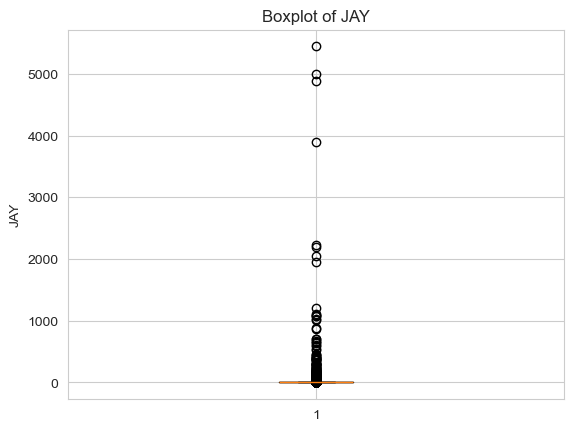

In [108]:
#Detecting Outliers for JAY Column
plt.figure()
plt.boxplot(employer_inf['JAY'].dropna())
plt.ylabel('JAY')
plt.title('Boxplot of JAY')
plt.show()

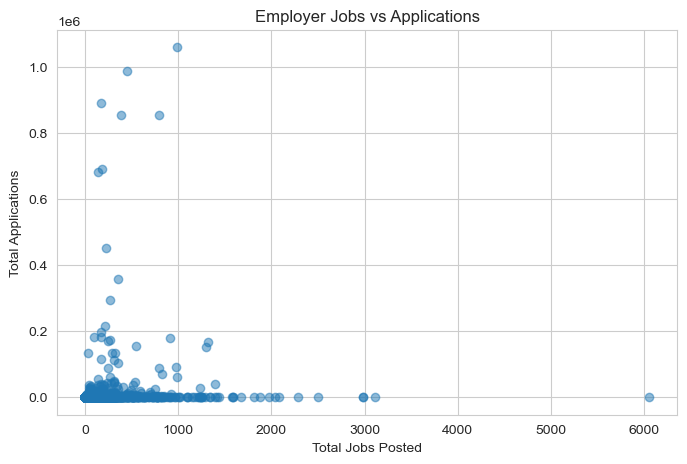

In [109]:
# Scatter plot of Jobs vs Applications
plt.figure(figsize=(8,5))
plt.scatter(employer_inf['total_jobs'], employer_inf['total_applications'], alpha=0.5)
plt.xlabel("Total Jobs Posted")
plt.ylabel("Total Applications")
plt.title("Employer Jobs vs Applications")
plt.show()

## Analyzing Event Participation
Focusing on what employers host events and weighting them based on student attendance

In [110]:
# Filter out invalid events 
valid_events = ep_joined['events_name'].notna() & (ep_joined['events_name'].str.strip() != '')

# Count total valid events per employer
total_events = ep_joined[valid_events].groupby('employer_id')['events_name'].count()
total_events = total_events.rename('total_events')

# Total student attendees per employer 
total_attendees = ep_joined.groupby('employer_id')['student_attendees_count'].sum()
total_attendees = total_attendees.rename('total_attendees')

# Add to employer_inf
if 'employer_name' not in employer_inf.columns:
    employer_inf['employer_name'] = ep_joined.groupby('employer_id')['employer_name'].first()

employer_inf['total_events'] = total_events
employer_inf['total_events'] = employer_inf['total_events'].fillna(0)
employer_inf['total_attendees'] = total_attendees
employer_inf['total_attendees'] = employer_inf['total_attendees'].fillna(0)

# Calculate Event Score
employer_inf['event_score'] = employer_inf['total_events'] + employer_inf['total_attendees']

In [111]:
#Summary Stats for event score column
event_score_stats = employer_inf['event_score'].describe()
event_score_stats

count    5.608900e+04
mean     2.725762e+02
std      1.068983e+04
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.452875e+06
Name: event_score, dtype: float64

In [112]:
# Top 10 employers by Event Score
top_event_employers = employer_inf.sort_values('event_score', ascending=False)
top_event_employers[['employer_name','total_events','total_attendees','event_score']].head(10)

,employer_name,total_events,total_attendees,event_score
employer_id,,,,
18383,jpmorganchase,107365.0,1345510.0,1452875.0
9226,ey,120262.0,920732.0,1040994.0
22003,amazon,48495.0,786255.0,834750.0
13661,morgan stanley,83250.0,623700.0,706950.0
39013,pwc,38233.0,499681.0,537914.0
14034,alphasights,76759.0,422825.0,499584.0
8594,deloitte,17253.0,402570.0,419823.0
14620,mckinsey & company,29370.0,319866.0,349236.0
172648,americorps,197380.0,151510.0,348890.0


In [113]:
# Bottom 10 employers by Event Score
bot_event_employers = employer_inf.sort_values('event_score', ascending=True)
bot_event_employers[['employer_name','total_events','total_attendees','event_score']].head(10)

,employer_name,total_events,total_attendees,event_score
employer_id,,,,
8406,von maur,0.0,0.0,0.0
1036330,one life,0.0,0.0,0.0
8412,thomson reuters,0.0,0.0,0.0
1036331,the mobile athlete: physical therapy performance,0.0,0.0,0.0
8417,None,0.0,0.0,0.0
8418,None,0.0,0.0,0.0
8419,c.h. robinson,0.0,0.0,0.0
8420,queen creek unified school district,0.0,0.0,0.0
1036337,None,0.0,0.0,0.0


## Analyzing Employer Consistency
Separate Measures for Jobs and Events

In [114]:
# Make sure dates are datetime
ep_joined['job_creation_date'] = pd.to_datetime(ep_joined['job_creation_date'], errors='coerce')
ep_joined['event_date'] = pd.to_datetime(ep_joined['event_date'], errors='coerce')

# Calculate active years per employer for jobs
jobs_years = ep_joined.groupby('employer_id')['job_creation_date'].agg(['min','max'])
jobs_years['active_years_jobs'] = jobs_years['max'].dt.year - jobs_years['min'].dt.year + 1

# Calculate active years per employer for events
events_years = ep_joined.groupby('employer_id')['event_date'].agg(['min','max'])
events_years['active_years_events'] = events_years['max'].dt.year - events_years['min'].dt.year + 1

# Add directly to employer_inf
employer_inf['active_years_jobs'] = employer_inf.index.map(jobs_years['active_years_jobs'])
employer_inf['active_years_events'] = employer_inf.index.map(events_years['active_years_events'])
employer_inf['active_years_jobs'] = employer_inf['active_years_jobs'].fillna(0)
employer_inf['active_years_events'] = employer_inf['active_years_events'].fillna(0)

# Calculate consistency
total_possible_years = ep_joined['job_creation_date'].dt.year.max() - ep_joined['job_creation_date'].dt.year.min() + 1
employer_inf['consistency_jobs'] = employer_inf['active_years_jobs'] / total_possible_years
employer_inf['consistency_events'] = employer_inf['active_years_events'] / total_possible_years

In [115]:
#Summary stats for consistency column
employer_inf['consistency_jobs'].describe()

count    56089.000000
mean         0.227418
std          0.294288
min          0.000000
25%          0.000000
50%          0.166667
75%          0.333333
max          1.000000
Name: consistency_jobs, dtype: float64

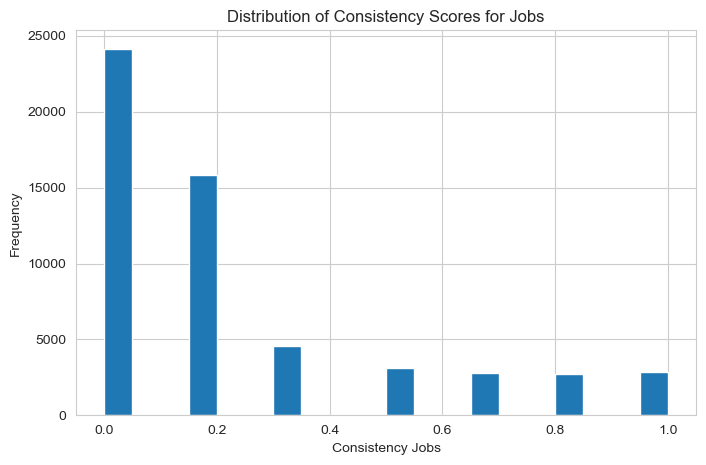

In [123]:
#Visualize Distribution of Consistency Scores for Jobs
plt.figure(figsize=(8,5))
plt.hist(employer_inf['consistency_jobs'], bins=20)
plt.xlabel('Consistency Jobs')
plt.ylabel('Frequency')
plt.title('Distribution of Consistency Scores for Jobs')
plt.show()

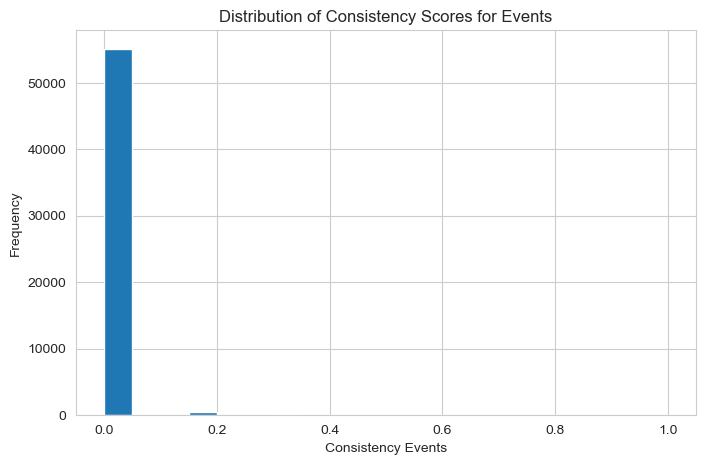

In [117]:
#Visualize Distribution of Consistency Scores for Events
plt.figure(figsize=(8,5))
plt.hist(employer_inf['consistency_events'], bins=20)
plt.xlabel('Consistency Events')
plt.ylabel('Frequency')
plt.title('Distribution of Consistency Scores for Events')
plt.show()

In [118]:
# View top 10 consistent employers for jobs
top_consistent_jobs = employer_inf.sort_values('consistency_jobs', ascending=False)
top_consistent_jobs[['employer_name','active_years_jobs','consistency_jobs']].head(10)

,employer_name,active_years_jobs,consistency_jobs
employer_id,,,
8513,nestlé purina,6.0,1.0
8501,aerotek,6.0,1.0
8412,thomson reuters,6.0,1.0
8489,mgm resorts international,6.0,1.0
8419,c.h. robinson,6.0,1.0
8449,wasserman next gen,6.0,1.0
452012,affinity dental management,6.0,1.0
8604,plante moran,6.0,1.0
70742,"i-park foundation, inc.",6.0,1.0


In [119]:
# View top 10 consistent employers for events
top_consistent_events = employer_inf.sort_values('consistency_events', ascending=False)
top_consistent_events[['employer_name','active_years_events','consistency_events']].head(10)

,employer_name,active_years_events,consistency_events
employer_id,,,
14034,alphasights,6.0,1.0
33968,citizens,6.0,1.0
15334,cushman & wakefield,6.0,1.0
23924,mayo clinic,6.0,1.0
32424,warner bros. discovery,6.0,1.0
13861,dell technologies,6.0,1.0
10918,liberty mutual insurance,6.0,1.0
12493,bank of america,6.0,1.0
19840,st. john's university,6.0,1.0


In [120]:
# View top 10 inconsistent employers for jobs
top_inconsistent_jobs = (
    employer_inf[employer_inf['employer_name'].notna()]
    .sort_values('consistency_jobs', ascending=True)
)

top_inconsistent_jobs[['employer_name','active_years_jobs','consistency_jobs']].head(10)

,employer_name,active_years_jobs,consistency_jobs
employer_id,,,
1060762,"provn, inc.",1.0,0.166667
1060757,artieve,1.0,0.166667
1060674,"mustard seed federal group, llc",1.0,0.166667
1060657,cinque chiropractic,1.0,0.166667
1060650,jms copiers inc,1.0,0.166667
1060623,ai made easier,1.0,0.166667
1060608,asjai lou casting,1.0,0.166667
1060391,veteran marketing group,1.0,0.166667
1060376,bikeeny caffe,1.0,0.166667


In [121]:
# View top 10 inconsistent employers for events
top_inconsistent_events = (
    employer_inf[employer_inf['employer_name'].notna()]
    .sort_values('consistency_events', ascending=True)
)

top_inconsistent_events[['employer_name','active_years_events','consistency_events']].head(10)

,employer_name,active_years_events,consistency_events
employer_id,,,
1061534,natural masters by new beginnings,0.0,0.0
1059677,nabs and babs,0.0,0.0
1059688,wrecking crew pictures,0.0,0.0
1059786,the stack marketplace,0.0,0.0
1059823,wonder,0.0,0.0
1059899,beach tree capital,0.0,0.0
1059917,zibbly,0.0,0.0
1059954,consumer experience llc,0.0,0.0
1060002,meg spellman interiors llc,0.0,0.0


**Note:** Some employer ids were associated with missing employer names and were dropped in the top_inconsistent dfs